# Using Causal Reasoning to Test Scientific Software

This tutorial provides a high-level overview of the primary features of the Causal Testing Framework (CTF).
It is adapted from [walkthrough material](https://doi.org/10.5281/zenodo.22146908) presented at RSECon26.

## Motivating Example: [Covasim](https://covasim.org/)
- Stochastic agent-based simulator for performing COVID-19 analyses
- Used to inform research studies and policy decisions in multiple countries including the US, UK, and Australia
- Important to make sure the model is working properly

> **Note:** The goal of this tutorial is not to thoroughly test Covasim (it is already well tested).
> We simply use it to illustrate the challenges of testing complex software and the solutions offered by the CTF.

### Testing Challenges
- Covasim was developed in an exploratory context - we do not know the expected output (e.g. number of infections) for any particular input. If we did, there would be no need for the model.
- Covasim is _nondeterministic_: its output can be random, and is not necessarily repeatable.
- Covasim has a large number of input and output parameters, with complex interactions. Some of these parameters are internal and cannot be directly manipulated.
- Covasim can take a long time to run, so the number of times we can run it is limited.

## (Statistical) Metamorphic Testing
Instead of testing that a simulation run of Covasim should lead to a particular number of infections when run with a particular set of parameter values, we can test that _changing_ a particular parameter leads to a corresponding _change_ in the number of infections.
This is known as [metamorphic testing(https://en.wikipedia.org/wiki/Metamorphic_testing).
For example, the `beta` parameter of Covasim effectively controls the "infectiousness" of the disease.
Intuitively, if we increase the infectiousness, we would expect more people to be infected, as long as the other parameters remain unchanged.
In other words, we want to validate that `beta` has a _positive causal effect_ on the number of infections.

Because Covasim is nondeterministic, we would need to test this statistically, using several runs of the software.
A naive way of doing this is to repeatedly run the software with two different values of `beta` and compare the mean number of infections associated with each.
However, this is not an efficient testing strategy if we have a lot of properties to investigate as we will require a lot of runs of Covasim.

## Causal Testing
Causal Testing offers a solution to the testing challenges presented above by allowing us to (statistically) investigate relationships between variables without needing to collect carefully controlled runs for each relationship under investigation.
Instead, randomised or even pre-existing runtime data can be used.
The key to this is [statistical causal inference](https://en.wikipedia.org/wiki/Causal_inference), although the CTF automates much of this, so you do not need a statistical background in order to use it.

The basic workflow is outlined below.
The user need only provide a directed acyclic graph (DAG) specifying the expected causal relationships in the software and a set of data with a column for each variable in the graph and where each row represents a run of the software.
The rest can be done automatically by the CTF, as we will show below.
If you are unsure of the causal relationships between variables in the software, the CTF has the capability to infer one for you from your data.
Check out our Causal Discovery tutorial for details.

![Causal Testing workflow schematic](../_static/images/testing-workflow.png)

### Causal DAG
The causal DAG specifies the expected causal relationships between variables in the system.
Each variable should have a node in the DAG.
Edges in the DAG represent causality, such that a node `X -> Y` represents `X` causing `Y`.

As an example, let's look at a DAG for a modelling scenario in Covasim, adapted from our [paper](https://doi.org/10.1145/3607184).
Here, we have one independent input parameter controlled by the user: the `location`.
Each `location` has a different dominant variant (Alpha, Beta, Delta, Gamma) of the disease, each of which has its own specific `beta` value (`beta`<sub>Alpha</sub> = 0 . 02672, `beta`<sub>Beta</sub> = 0 . 016, `beta`<sub>Gamma</sub> = 0 . 0352, `beta`<sub>Delta</sub> = 0 . 0328 ).
Locations also have their own population demographics, characterised by the `household_size` and `average_age`, which then determines the level of `contact` at `work`, `school`, and the `community` within the population.
The output of the model is the total number of `infections` that occurred during the simulation.

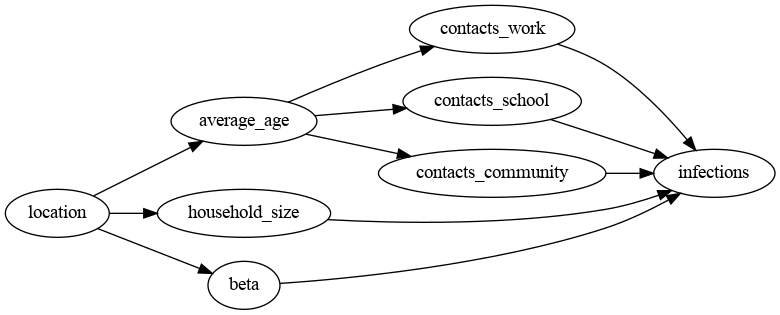

In [1]:
from IPython.display import Image, display
import networkx as nx
from causal_testing.examples.covasim import doubling_beta as cv

dag=nx.DiGraph(nx.nx_pydot.read_dot(cv.dag_path))
P = nx.nx_pydot.to_pydot(dag)
P.set_node_defaults(shape="ellipse", style="filled", fillcolor="lightblue")
P.set_graph_defaults(rankdir="LR")
png_data = P.create_png(prog="dot")
display(Image(png_data))

### Data
To run causal tests, we need data for each node in the DAG from several runs of the software.
A major advantage of causal testing is that this data need not be controlled - you can simply collect a bunch of random runs of your system, or even use pre-existing data if you have it.
Here, we have collected 10,000 runs of Covasim

In [2]:
cv.df

,location,average_age,beta,household_size,contacts_school,contacts_work,contacts_community,infections
0,mongolia,29.401,0.01465,3.443,20.014,16.000,19.998,791634
1,mongolia,29.420,0.01561,3.452,20.012,15.998,19.997,811405
2,mongolia,29.393,0.01575,3.449,19.975,16.001,20.007,814960
3,mongolia,29.391,0.01698,3.448,20.006,15.997,19.994,834737
4,mongolia,29.395,0.01876,3.440,20.001,16.003,19.997,858812
...,...,...,...,...,...,...,...,...
4675,greece,45.217,0.02324,1.883,20.004,16.001,20.001,908808
4676,greece,45.182,0.02644,1.887,19.995,15.988,20.003,928411
4677,greece,45.224,0.02358,1.887,20.009,16.005,19.999,911786
4678,greece,45.279,0.02685,1.887,20.001,16.002,19.994,931457


In [4]:
from causal_testing.examples.covasim import doubling_beta as cv

from tempfile import TemporaryDirectory
from pathlib import Path

print(plp.dag_path)
print(cv.dag_path)

with TemporaryDirectory() as tmp:
    output_path = Path(tmp)/"causal_test_results.json"
    !causal-testing test --data-paths "{cv.data_path}" --dag-path "{cv.dag_path}" --generate --output "{output_path}"

/home/michael/Documents/CITCoM/CausalTestingFramework/causal_testing/examples/poisson_line_process/dag.dot
/home/michael/Documents/CITCoM/CausalTestingFramework/causal_testing/examples/covasim/doubling_beta/dag.dot
2026-10-27 16:30:37 - causal_testing.causal_testing_framework - INFO - Loading DAG from /home/michael/Documents/CITCoM/CausalTestingFramework/causal_testing/examples/covasim/doubling_beta/dag.dot
2026-10-27 16:30:37 - causal_testing.causal_testing_framework - INFO - DAG loaded with 8 nodes and 11 edges
2026-10-27 16:30:37 - causal_testing.causal_testing_framework - INFO - Loading data from 1 source(s)
2026-10-27 16:30:37 - causal_testing.causal_testing_framework - INFO - Initial data shape: (4680, 8)
2026-10-27 16:30:37 - causal_testing.causal_testing_framework - INFO - Running causal tests...
100%|██████████████████████████████████████████| 40/40 [00:01<00:00, 26.40it/s]
2026-10-27 16:30:39 - causal_testing.causal_testing_framework - INFO - Saving results to /tmp/tmphqfsxye